In [95]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = pd.read_csv("50_Startups.csv")
data = pd.concat([data.drop("State", axis=1), pd.get_dummies(data["State"], drop_first=True)], axis=1)

train_ratio = 0.8
test_ratio = 0.2
shuffled_df = data.sample(frac=1, random_state=0).reset_index(drop=True)
split_index = int(len(shuffled_df) * train_ratio)

train_df = shuffled_df[:split_index]
test_df = shuffled_df[split_index:]

features = ["R&D Spend", "Administration", "Marketing Spend", "Florida", "New York"]
target = "Profit"

X_train = train_df[features].values
y_train = train_df[target].values
X_test = test_df[features].values
y_test = test_df[target].values

In [96]:
def linear_regression(X, y, learning_rate=0.01, epochs=1000):
    X = np.array(X, dtype=float)
    y = np.array(y, dtype=float)
    X_mean = np.mean(X, axis=0)
    X_std = np.std(X, axis=0)
    X_scaled = (X - X_mean) / (X_std + 1e-8)

    n_samples, n_features = X_scaled.shape
    m = np.zeros(n_features)
    c = 0.0
    loss_history = []

    for epoch in range(epochs):
        y_pred = np.dot(X_scaled, m) + c

        dm = (-2 / n_samples) * np.dot(X_scaled.T, (y - y_pred))
        dc = (-2 / n_samples) * np.sum(y - y_pred)

        m = m - (learning_rate * dm)
        c = c - (learning_rate * dc)

        loss = np.mean((y - y_pred) ** 2)
        loss_history.append(loss)
        if epoch % 100 == 0:
            print(f"Epoch {epoch:<4} | Loss: {loss:.2f}")
    final_loss = np.mean((y - (np.dot(X_scaled, m) + c)) ** 2)
    print(f"Final Loss: {final_loss:.2f}")

    return m, c, loss_history, X_mean, X_std

In [97]:
m, c, loss_history, X_mean, X_std = linear_regression(X_train, y_train, learning_rate=0.01, epochs=1000)

Epoch 0    | Loss: 14083354751.00
Epoch 100  | Loss: 349074865.68
Epoch 200  | Loss: 106278893.85
Epoch 300  | Loss: 92804308.73
Epoch 400  | Loss: 88246172.84
Epoch 500  | Loss: 86139839.97
Epoch 600  | Loss: 85152522.39
Epoch 700  | Loss: 84689445.95
Epoch 800  | Loss: 84472241.76
Epoch 900  | Loss: 84370362.12
Final Loss: 84322575.35


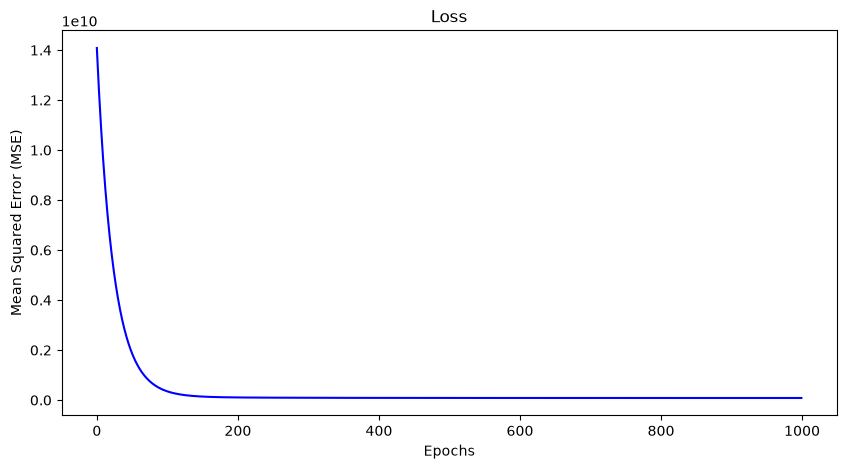

In [98]:
plt.figure(figsize=(10, 5))
plt.plot(loss_history, color='blue')
plt.title("Loss")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error (MSE)")
plt.show()

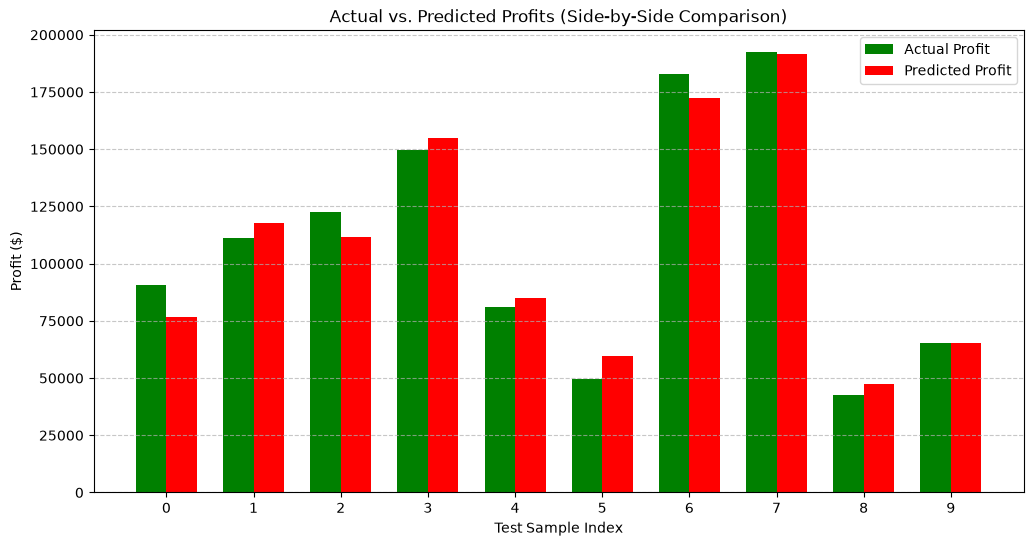

In [99]:
X_test_scaled = (X_test - X_mean) / (X_std + 1e-8)
pred_values = np.dot(X_test_scaled, m) + c

x_indices = np.arange(len(y_test))
bar_width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(x_indices - bar_width/2, y_test, width=bar_width, color='green', label="Actual Profit")
plt.bar(x_indices + bar_width/2, pred_values, width=bar_width, color='red', label="Predicted Profit")

plt.title("Actual vs. Predicted Profits (Side-by-Side Comparison)")
plt.xlabel("Test Sample Index")
plt.ylabel("Profit ($)")

plt.xticks(x_indices) 

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()